# Deep Impact - The hazard of Small Asteroids

Team: Gaspra

## Functionalities

The `deepimpact` package predicts a small asteroid's journey as it breaches the earth's atmosphere and approaches collision to the ground. 

Throughout its descent, the asteroid may break up in smaller pieces: this event is called an *airburst*. If it doesn't break, and reached the ground in one piece, it is called *cratering*. The loss of energy peaks at these two moments: break-up of the asteroid and impact with the ground respectively. The functions provided also describe how the kinetic energy is progressively lost.

Additionally, one the package functionalities is to find the coordinates of the impact, as well as the damage radii, i.e. the reach of the energy outburst. These two elements (ground zero point and damage radii) can also be plotted on a map.

This file documents each function, detailing its inputs and outputs, as well as their interpretation and usage.

The core functionalities are:
- Airburst solver:
    - Determine the status of the asteroid (velocity, mass, ...) at each time step from the start of the simulation to the moment it hits the ground.
    - Calculate the kinetic energy lost at each time step.
    - Obtain information about the impact event.
- Mapper:
    - Find the location of the impact, and the reach of the damage (radius).
    - Determine postcodes and population involved.
    - Project onto a map. 

## Airburst Solver

### Tracking the path: solve_atmospheric_entry

<table style="border: none; border-collapse: collapse;">
<tr style="border: none;">
<td style="border: none; vertical-align: top;">

An asteroid's journey through the earth's atmosphere and to the ground at the moment of impact is described by the following variables at each point in time:

- Speed ($v$): distance travelled in a unit of time,
- Mass ($m$): decreases as the asteroid starts disintegrating,
- Angle ($\theta$): inclination with respect to the horizontal,
- Altitude ($z$): distance from the ground,
- Displacement ($x$): horizontal distance travelled from the initial point.

</td>
<td style="width: 250px; border: none; vertical-align: top;">
<img src="../images/variables.png" width="250">
</td>
</tr>
</table>

The following set of ordinary differential equations models the dynamic of the asteroid in Earth's atmosphere before break-up:

$$
\begin{aligned}
& \\
\frac{dv}{dt} & = \frac{-C_D\rho_a A v^2}{2 m} + g \sin \theta \\[2ex]
\frac{dm}{dt} & = \frac{-C_H\rho_a A v^3}{2 Q} \\[2ex]
\frac{d\theta}{dt} & = \frac{g\cos\theta}{v} - \frac{C_L\rho_a A v}{2 m} - \frac{v\cos\theta}{R_P + z} \\[2ex]
\frac{dz}{dt} & = -v\sin\theta \\[2ex]
\frac{dx}{dt} & = \frac{v\cos\theta}{1 + z/R_P}
\end{aligned}
$$
where $A$ is the cross-sectional area of the astoroid at a moment in time.

The constants in these equations are:
- $C_D$: Drag coefficient
- $C_H$: Heat Transfer coefficient
- $Q$: Heat of ablation (J/kg)
- $C_L$: Lift coefficient
- $R_P$: Planet radius (Earth; m)

The break-up of the asteroid occurs when the ram pressure (pressure exerted on a body moving through a fluid medium) of the air interacting with the asteroid exceeds the strength of the asteroid ($Y$):
$$\rho_a v^2 = Y$$
At this point the asteroid starts spreading, with its radius growing. The spreading accelartion is described by the following second order derivative:

$$ r\frac{d^2r}{dt^2} = C_D \frac{\rho_a}{\rho_m} v^2$$

where:
- $r$ is the asteroid radius at that moment in time
- $C_D$ is the drag coefficient
- $\rho_a$ is the air's density at the current altitude
- $\rho_m$ is the asteroid density, assumed to be constant

The asteroid (now a collection of spread out rocks) stops spreading when lateral expansion ($r / r_0$, $r_0$ = original radius) reaches a limit known as the pancake factor ($f_p$), which refers to the pancake shape achieved through the spreading:
$$\frac{r}{r_0} = f_p$$
Note that the spreading rate equation is only applied alongside the other ODEs during the spreading phase, and can be set to zero before and after.

The way we go about obtaining the state of the asteroid at each point is by defining an initial value problem (IVP), which in this case takes the shape of a coupled set of ordinary differential equations together with an initial condition.
The chosen solver method is classical fourth-order Runge-Kutta (RK4), for the following reasons:
- **Accuracy.** It is fourth-order accurate: in the small-step limit, halving the time step reduces the global error approximately by a factor of $2^4 = 16$. Our implementation also bounds the internal step size and uses smaller steps near output and event times to maintain accuracy.
- **Cost.** It provides a good balance between accuracy and computational cost. Each step evaluates the coupled derivatives at the start ($k1: t$), midpoint ($k2, k3: t + h/2$) and end of the interval ($k4: t + h$), rather than using only a single slope as a first-order method would.
- **Clarity.** It is explicit and straightforward to implement, requiring only derivative evaluations and no iterative solution of a nonlinear system at each step. Is is therefore well suited to the non-linear, coupled atmospheric-entry equations.
- **Flexibility.** It allows the different phases to be handled explicitly: intact, spreading and capped states can be set before each step, and additional step refinements can locate breakup, the pancake limit and ground impact. RK4 is conditionally stable, so the small internal step size and event-based step shortening are important.
- **Smooth, non-stiff, low-dimensional system.** Within each phase, the seven state equations (v, m, $\theta$, z, x, r, dr/dt) are smooth, state-dependent differential equations. The changes from intact to spreading to capped are handled explicitly and locally, including refinement around events. The system is low-dimensional and does not appear to contain widely separated fast and slow timescales, so an implicit method is not evidently necessary. 

RK4 is therefore a reasonable explicit solver: it is straightforward to implement and, with the bounded time steps used here, provides sufficient accuracy without the additional cost of solving nonlinear systems at every step.

Before proceeding to resolve and analyse any asteroid impact, the planet where this occurs must be defined. We do this by initialising an object from the class `Planet`, whose can be found in the `deepimpact/solver.py` file. 
The required inputs are:
- :`atmos_func`: the choice of atmospheric function, which computes the density of the atmosphere:
    - `'exponential'`: $\rho = \rho_a \cdot e^{-z/H}$, where $H$ is the atmospheric scale height 
    - `'tabular'`: density at each altitude obtained from a separate file
    - `'constant'`: density is constant and takes the value passed as input
- `atmos_filename`: the file with the density per altitude: this is optional and needed only when `atmos_func` is `'tabular'`.
- `Cd`: the drag coefficient. 
    - $\geq 0$, finite.
- `Ch`; The heat transfer coefficient. 
    - $> 0$, finite.
- `Q`: The heat of ablation. [$J/kg$]
    - $> 0$, finite.
- `Cl`: Lift coefficient.
    - $\geq 0$, finite.
- `Rp`: Planet radius [m]
    - $> 0$
- `rho0` : Air density at zero altitude [$kg/m^3$]
    - $\geq 0$, finite.
- `g` : surface gravity [$m/s^2$]
    - $\geq 0$, finite.
- `H`: atmospheric scale height [$m$]
    - $>0$, finite.
- `pancake_factor`:
    - $\geq 1$, finite.

The following code snippet shows an example of how to initialise the object. The [Chelyabinsk](https://en.wikipedia.org/wiki/Chelyabinsk_meteor) event is scientifically observed impact data which can be used as a running example. Central London provides the UK-specific location used to demonstrate the damage mapper.

In [1]:
import deepimpact

# Earth-wide atmospheric and physical constants
earth = deepimpact.Planet(
    atmos_func="exponential",
    Cd=1.0,
    Ch=0.1,
    Q=1e7,
    Cl=1e-3,
    Rp=6371e3,
    rho0=1.2,
    g=9.81,
    H=8000.0,
    pancake_factor=6.5,
)

# Alternatively, for a tabular atmosphere
earth_tabular = deepimpact.Planet(
    atmos_func="tabular",
    atmos_filename="../resources/AltitudeDensityTable.csv",
    Cd=1.0,
    Ch=0.1,
    Q=1e7,
    Cl=1e-3,
    Rp=6371e3,
    rho0=1.2,
    g=9.81,
    H=8000.0,
    pancake_factor=6.5,
)

Once that is done, we can call the functions of the class `Planet` to study the asteroid impact.

The core solver function is `solve_atmospheric_entry`. Its inputs are as follows:
- `radius`: the radius of the asteroid in meters
    - $> 0$, finite
- `velocity`: the entry speed of the asteroid in meters/second
    - $> 0$, finite
- `density`: the density of the asteroid in $kg/m^3$
    - $> 0$, finite
- `strength`: the strength of the asteroid (i.e. the maximum pressure it can take before fragmenting) in $N/m^2$
    - $\geq 0$
- `angle` : the initial trajectory angle of the asteroid to the horizontal. 
    - $0 \leq \theta \leq 90$ 
    - If `radians` is set to True, the input must be between $0$ and $\pi/2$ radians.
- `init_altitude` : initial altitude in m; 
    - $\geq 0$, finite.
- `dt` : the positive, finite output timestep, in $s$, i.e. the time difference between one entry and the next in the results table.
    - NOTE: Very small values produce many output rows and can make the simulation unnecessarily slow. The standard choice is $dt = 0.05 s$
- `radians`: boolean indicating whether angles should be given in degrees or radians. Angles returned in the dataframe will have the same units as the input
    - The default is `False`. 

The next code snippet is an example call for the Chelyabinsk case. We will then go through the output.

In [2]:
# Chelyabinsk as an example asteroid
chelyabinsk = earth.solve_atmospheric_entry(
    radius=10.0,
    velocity=19.2e3,
    density=3300.0,
    strength=1e6,
    angle=18.3,
    init_altitude=100e3,
    dt=0.05,
)

chelyabinsk.head()

,velocity,mass,angle,altitude,distance,radius,spreading_rate,time
0,19200.000000,1.382301e+07,18.300000,100000.000000,0.000000,10.0,0.0,0.00
1,19200.153032,1.382301e+07,18.293319,99698.619180,897.405109,10.0,0.0,0.05
2,19200.305972,1.382300e+07,18.286638,99397.342246,1794.893758,10.0,0.0,0.10
3,19200.458820,1.382300e+07,18.279955,99096.169218,2692.465928,10.0,0.0,0.15
4,19200.611575,1.382300e+07,18.273272,98795.100114,3590.121599,10.0,0.0,0.20


The output shows 7 columns, each one representing one aspect the state of the asteroid at a given time. These columns are:
- Velocity: speed of the asteroid at time $t = i \cdot dt$, where $i$ is the row index.
- Mass: mass of asteroid at time step $t = i\cdot dt$
- Angle: angle respect to the horizontal axis at time step $t = i\cdot dt$
- Altitude: altitude (i.e. distance from the ground) of the asteroid at time step $t = i\cdot dt$
- Distance: distance travelled horizontally from the at time step $t = i\cdot dt$
- Radius: radius of the asteroid at time step $t = i\cdot dt$. This might expand upon break-up.
- Spreading rate: how much the radius has expanded by time step $t = i\cdot dt$

Each row take a snapshot of the asteroid through its journey to the planet. 

For clarity, even if altitude $z=0$ is not reached at a time that is a multiple of $dt$, it is added as the last entry of the data frame, should the asteroid actually reach the surface of the planet.

In [3]:
n_rows = len(chelyabinsk)

print(rf"{n_rows} rows of data for dt = 0.05 and initial altitude z = 10^6 m")

5149 rows of data for dt = 0.05 and initial altitude z = 10^6 m


In [4]:
chelyabinsk_velocity       = chelyabinsk['velocity']
chelyabinsk_mass           = chelyabinsk['mass']
chelyabinsk_altitude       = chelyabinsk['altitude']
chelyabinsk_distance       = chelyabinsk['distance']
chelyabinsk_radius         = chelyabinsk['radius']
chelyabinsk_spreading_rate = chelyabinsk['spreading_rate']
chelyabinsk_time           = chelyabinsk['time']

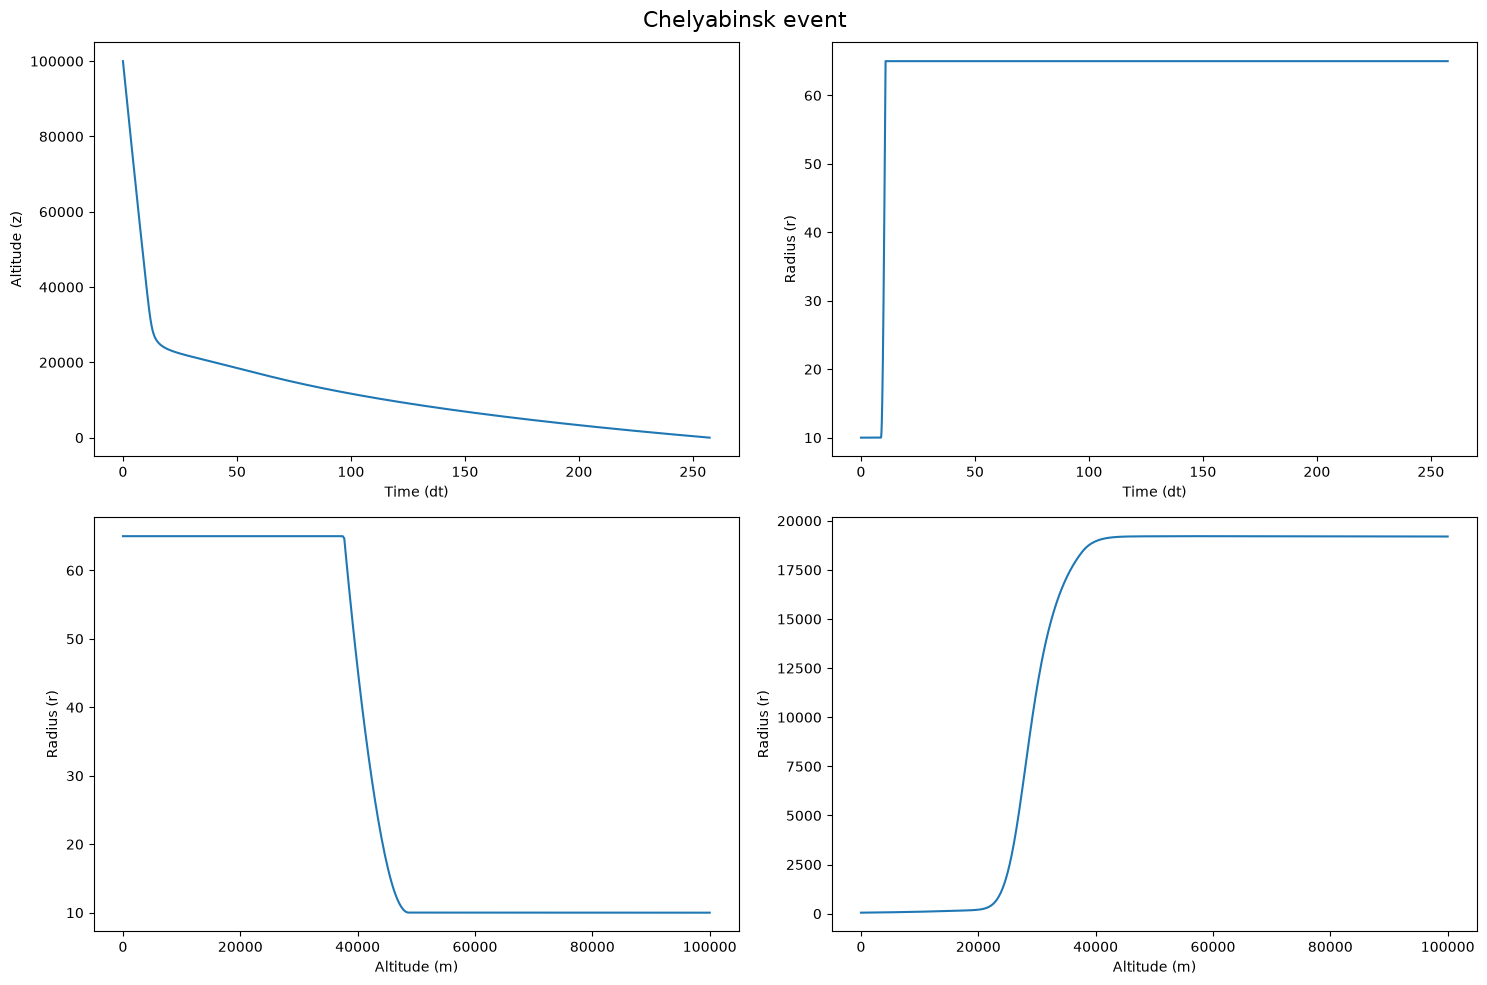

In [5]:
import matplotlib.pyplot as plt

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15,10))

ax1.plot(chelyabinsk_time, chelyabinsk_altitude)
ax1.set_xlabel('Time (dt)')
ax1.set_ylabel('Altitude (z)')

ax2.plot(chelyabinsk_time, chelyabinsk_radius)
ax2.set_xlabel('Time (dt)')
ax2.set_ylabel('Radius (r)')

ax3.plot(chelyabinsk_altitude, chelyabinsk_radius)
ax3.set_xlabel('Altitude (m)')
ax3.set_ylabel('Radius (r)')

ax4.plot(chelyabinsk_altitude, chelyabinsk_velocity)
ax4.set_xlabel('Altitude (m)')
ax4.set_ylabel('Radius (r)')

fig.suptitle("Chelyabinsk event", fontsize=16)
fig.tight_layout()
plt.show()

### Observing the energy loss: calculate_energy

The solver output contains the asteroid's mass, velocity and altitude at each sampled time. `calculate_energy` uses these values to estimate the kinetic energy lost per kilometre of descent. It reads the supplied result DataFrame and returns a **copy** with one additional column, `dedz`; the original `chelyabinsk` DataFrame is unchanged.

The kinetic energy at sample \(i\) is

$$
K_i = \frac{1}{2} m_i v_i^2.
$$

The function estimates the derivative of kinetic energy with respect to altitude, \(dK/dz\), with `numpy.gradient`, using the altitude values as the sample coordinates. It uses central differences at interior samples and one-sided differences at the endpoints, and it can account for uneven spacing between altitude samples. As a finite-difference estimate, its accuracy depends on the spacing and smoothness of the sampled trajectory. The derivative is converted from J/m to kilotons of TNT per kilometre:

$$
\mathrm{dedz} = \frac{dK}{dz} \times \frac{1000}{4.184\times 10^{12}}.
$$

For a descending object that is losing kinetic energy, `dedz` is usually positive: both kinetic energy and altitude decrease together. A single sample, repeated local altitudes, or invalid values do not provide a usable derivative, so the affected value is `NaN`.

In [6]:
# Add the energy-loss rate to a copy of the Chelyabinsk trajectory.
chelyabinsk_energy = earth.calculate_energy(chelyabinsk)

chelyabinsk_energy[[
    "time", "altitude", "mass", "velocity", "dedz"
]].head()

,time,altitude,mass,velocity,dedz
0,0.00,100000.000000,1.382301e+07,19200.000000,-0.031850
1,0.05,99698.619180,1.382301e+07,19200.153032,-0.031828
2,0.10,99397.342246,1.382300e+07,19200.305972,-0.031805
3,0.15,99096.169218,1.382300e+07,19200.458820,-0.031782
4,0.20,98795.100114,1.382300e+07,19200.611575,-0.031758


The preview shows the estimated energy loss rate alongside the state variables used to calculate it. `dedz` is a rate per unit altitude, not a total energy for the row. Its largest value marks the point of greatest energy loss per kilometre and is used by `analyse_outcome` when identifying an airburst peak.

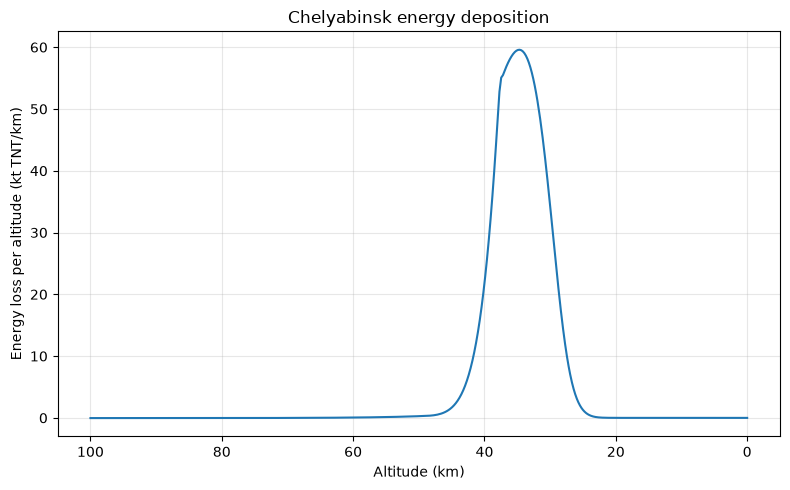

In [7]:
# Plot energy loss per kilometre against altitude.
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    chelyabinsk_energy["altitude"] / 1000.0,
    chelyabinsk_energy["dedz"],
)
ax.invert_xaxis()  # Show the descent from high altitude towards the ground.
ax.set_xlabel("Altitude (km)")
ax.set_ylabel("Energy loss per altitude (kt TNT/km)")
ax.set_title("Chelyabinsk energy deposition")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

### Analysing the outcome: analyse_outcome

### What `analyse_outcome` returns

`analyse_outcome` takes the trajectory **with** its `dedz` column, so call `calculate_energy` first. It finds the row with the largest finite `dedz` and uses the peak altitude relative to the asteroid radius to classify the result:

- **Airburst:** the energy-deposition peak is above the ground. The reported altitude, distance, angle and `burst_peak_dedz` come from the peak row. `burst_energy` is the kinetic energy lost between the initial row and that peak.
- **Cratering:** the peak is at or close to the ground according to the implementation's condition `peak altitude <= peak radius`. The reported altitude is zero and the distance, angle and `burst_peak_dedz` come from the final row. The reported energy is the larger of the total kinetic energy lost by the final row and the kinetic energy remaining at impact.

The returned dictionary has these fields:

| Key | Meaning | Units |
|---|---|---|
| `outcome` | `Airburst`, `Cratering`, or `Unknown` | — |
| `burst_peak_dedz` | Energy-loss rate at the selected peak row (airburst) or final row (cratering) | kt TNT/km |
| `burst_altitude` | Height assigned to the event; ground level for cratering | m |
| `burst_distance` | Horizontal distance from the trajectory's starting point | m |
| `burst_energy` | Estimated event energy | kt TNT |
| `burst_angle` | Trajectory angle at the selected event row | Same units as the input angle |

If the DataFrame is empty or contains no finite `dedz` values, the function returns an `Unknown` outcome with zero-valued event fields.

In [8]:
# Classify the event using the trajectory and its calculated dedz column.
chelyabinsk_outcome = earth.analyse_outcome(chelyabinsk_energy)
chelyabinsk_outcome

{'outcome': 'Airburst',
 'burst_peak_dedz': np.float64(59.584482768703396),
 'burst_altitude': np.float64(34648.52586870031),
 'burst_distance': np.float64(204623.20626758793),
 'burst_energy': np.float64(303.88259129718165),
 'burst_angle': np.float64(16.77069865363489)}

The displayed dictionary summarises the event inferred from this simulated trajectory. The classification is based on the sampled solution and the calculated energy-deposition curve; it is therefore an analysis of the model output, rather than an independent observation of the real event.

## Extended functionality: fitting the Chelyabinsk event

This notebook estimates the meteoroid radius, strength, and pancake factor that best match the supplied Chelyabinsk energy-deposition curve.

The measured entry velocity (19.2 km/s), density (3300 kg/m^3), and angle (18.3 degrees) are fixed. The fit searches the ranges in the project brief: radius 5-15 m, strength 0.1-10 MPa, and pancake factor 2-10. The solver's initial altitude is 100 km.

The objective is a least-squares match to the observed energy-deposition values, scaled by the largest observed value. Differential evolution searches the bounded parameter space; bounded least squares then refines that candidate. The project ODE solver still computes each trajectory. The optimizer does not replace the ODE solver.

This section is a guided version of the [standalone Chelyabinsk fitting example](../examples/chelyabinsk_fit.ipynb). `scipy.optimize` is used only for this extension task.

In [9]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import differential_evolution, least_squares

# Locate the repository so the notebook works when opened from the repo root
# or from its own examples directory.
repo_root = next(
    parent for parent in [Path.cwd(), *Path.cwd().parents]
    if (parent / "deepimpact").is_dir() and (parent / "resources").is_dir()
)
sys.path.insert(0, str(repo_root))
from deepimpact.solver import Planet

plt.style.use("seaborn-v0_8-whitegrid")


## 1. Load and inspect the measured curve

The CSV contains altitude in kilometres and inferred energy loss per unit altitude in kt TNT/km. The values are sorted by altitude for interpolation and plotting. The known entry conditions come from the project brief; radius, strength, and pancake factor are the fitted quantities.


Observation points: 128
Observed altitude range: 21.62 to 42.19 km
Known entry conditions: {'velocity': 19200.0, 'density': 3300.0, 'angle': 18.3, 'init_altitude': 100000.0}
Search bounds: {'radius_m': (5.0, 15.0), 'strength_mpa': (0.1, 10.0), 'pancake_factor': (2.0, 10.0)}


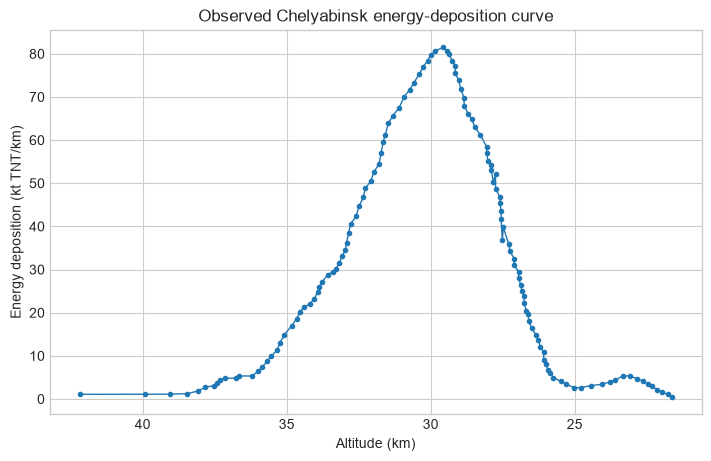

In [10]:
observations = pd.read_csv(
    repo_root / "resources" / "ChelyabinskEnergyAltitude.csv"
).sort_values("Height (km)").reset_index(drop=True)
observed_altitude_km = observations["Height (km)"].to_numpy()
observed_dedz = observations["Energy Per Unit Length (kt Km^-1)"].to_numpy()

known_entry = {
    "velocity": 19_200.0,       # m/s
    "density": 3300.0,         # kg/m^3
    "angle": 18.3,              # degrees to horizontal
    "init_altitude": 100_000.0, # m
}
parameter_bounds = {
    "radius_m": (5.0, 15.0),
    "strength_mpa": (0.1, 10.0),
    "pancake_factor": (2.0, 10.0),
}

print(f"Observation points: {len(observations)}")
print(f"Observed altitude range: {observed_altitude_km.min():.2f} to {observed_altitude_km.max():.2f} km")
print("Known entry conditions:", known_entry)
print("Search bounds:", parameter_bounds)

fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
ax.plot(observed_altitude_km, observed_dedz, "o-", markersize=3, linewidth=1)
ax.set(
    xlabel="Altitude (km)",
    ylabel="Energy deposition (kt TNT/km)",
    title="Observed Chelyabinsk energy-deposition curve",
)
ax.invert_xaxis()
plt.show()


## 2. Define how a parameter set produces a model curve

For each candidate parameter set, create a `Planet` with the requested pancake factor, solve the entry using the project's `solve_atmospheric_entry`, and calculate `dedz` from the returned dataframe. Interpolate the model deposition onto the observed altitudes so the model and measurements can be compared point by point.

A cache avoids rerunning the same candidate if the optimizer revisits it. `dt=0.05 s` is used during the fit to keep the search practical while resolving the trajectory sufficiently for this curve comparison.


In [11]:
fit_dt = 0.05
prediction_cache = {}

def predict_dedz(parameters):
    """Return model dedz at each measured altitude for [radius, strength MPa, pancake]."""
    radius_m, strength_mpa, pancake_factor = map(float, parameters)
    cache_key = tuple(np.round([radius_m, strength_mpa, pancake_factor], 8))
    if cache_key in prediction_cache:
        return prediction_cache[cache_key]

    planet = Planet(pancake_factor=pancake_factor)
    trajectory = planet.solve_atmospheric_entry(
        radius=radius_m,
        velocity=known_entry["velocity"],
        density=known_entry["density"],
        strength=strength_mpa * 1e6,
        angle=known_entry["angle"],
        init_altitude=known_entry["init_altitude"],
        dt=fit_dt,
    )
    energy = planet.calculate_energy(trajectory)
    model_altitude_km = energy["altitude"].to_numpy() / 1000.0
    model_dedz = energy["dedz"].to_numpy()
    valid = np.isfinite(model_altitude_km) & np.isfinite(model_dedz)
    order = np.argsort(model_altitude_km[valid])
    sorted_altitude = model_altitude_km[valid][order]
    sorted_dedz = model_dedz[valid][order]

    if (
        observed_altitude_km.min() < sorted_altitude.min()
        or observed_altitude_km.max() > sorted_altitude.max()
    ):
        raise ValueError("The model trajectory does not cover all observed altitudes.")

    prediction = np.interp(
        observed_altitude_km,
        sorted_altitude,
        np.maximum(sorted_dedz, 1e-8),
    )
    prediction_cache[cache_key] = prediction
    return prediction

observed_scale = np.max(observed_dedz)

def scaled_residuals(parameters):
    """Residuals in observed units, scaled by the observed curve's peak."""
    return (predict_dedz(parameters) - observed_dedz) / observed_scale


## 3. Search and refine the fit

The bounded search only explores the ranges specified above. A fixed random seed makes the global-search stage reproducible. The second stage refines the best candidate. The reported fit is the best result found by this objective and search budget; it does not prove that the inferred physical parameters are unique.


In [12]:
search = differential_evolution(
    lambda parameters: np.mean(scaled_residuals(parameters) ** 2),
    bounds=[
        parameter_bounds["radius_m"],
        parameter_bounds["strength_mpa"],
        parameter_bounds["pancake_factor"],
    ],
    seed=20261117,
    popsize=6,
    maxiter=12,
    tol=0.005,
    polish=False,
    workers=1,
)

refined = least_squares(
    scaled_residuals,
    x0=search.x,
    bounds=([5.0, 0.1, 2.0], [15.0, 10.0, 10.0]),
    x_scale=[5.0, 3.0, 4.0],
    diff_step=[0.01, 0.02, 0.01],
    max_nfev=60,
)

best_parameters = refined.x
best_radius_m, best_strength_mpa, best_pancake_factor = best_parameters
best_model_dedz = predict_dedz(best_parameters)

# Use the earlier A2 example parameters as a baseline for comparison.
baseline_parameters = np.array([10.0, 1.0, 6.5])
baseline_model_dedz = predict_dedz(baseline_parameters)

def fit_metrics(model):
    residual = model - observed_dedz
    rmse = np.sqrt(np.mean(residual**2))
    normalized_rmse = rmse / observed_scale
    r_squared = 1.0 - np.sum(residual**2) / np.sum(
        (observed_dedz - np.mean(observed_dedz)) ** 2
    )
    return rmse, normalized_rmse, r_squared

baseline_metrics = fit_metrics(baseline_model_dedz)
best_metrics = fit_metrics(best_model_dedz)
fit_summary = pd.DataFrame(
    [
        {
            "case": "Baseline (10 m, 1 MPa, 6.5)",
            "radius (m)": baseline_parameters[0],
            "strength (MPa)": baseline_parameters[1],
            "pancake factor": baseline_parameters[2],
            "RMSE (kt/km)": baseline_metrics[0],
            "RMSE / observed peak": baseline_metrics[1],
            "R squared": baseline_metrics[2],
        },
        {
            "case": "Best fit found",
            "radius (m)": best_radius_m,
            "strength (MPa)": best_strength_mpa,
            "pancake factor": best_pancake_factor,
            "RMSE (kt/km)": best_metrics[0],
            "RMSE / observed peak": best_metrics[1],
            "R squared": best_metrics[2],
        },
    ]
)
print(f"Global-search evaluations: {search.nfev}")
print(f"Local-refinement evaluations: {refined.nfev}")
print(f"Fit time step: {fit_dt} s")
fit_summary


Global-search evaluations: 234
Local-refinement evaluations: 17
Fit time step: 0.05 s


,case,radius (m),strength (MPa),pancake factor,RMSE (kt/km),RMSE / observed peak,R squared
0,"Baseline (10 m, 1 MPa, 6.5)",10.000000,1.000000,6.500000,32.180078,0.394823,-0.527154
1,Best fit found,9.012086,4.728566,6.290495,7.356473,0.090258,0.920192


## 4. Compare observed and fitted curves

The left panel overlays measurements, the best-fit model, and the baseline model. The right panel shows the best-fit residual (model minus observation) in kt/km. This makes it easier to see both the overall match and where the model remains high or low.


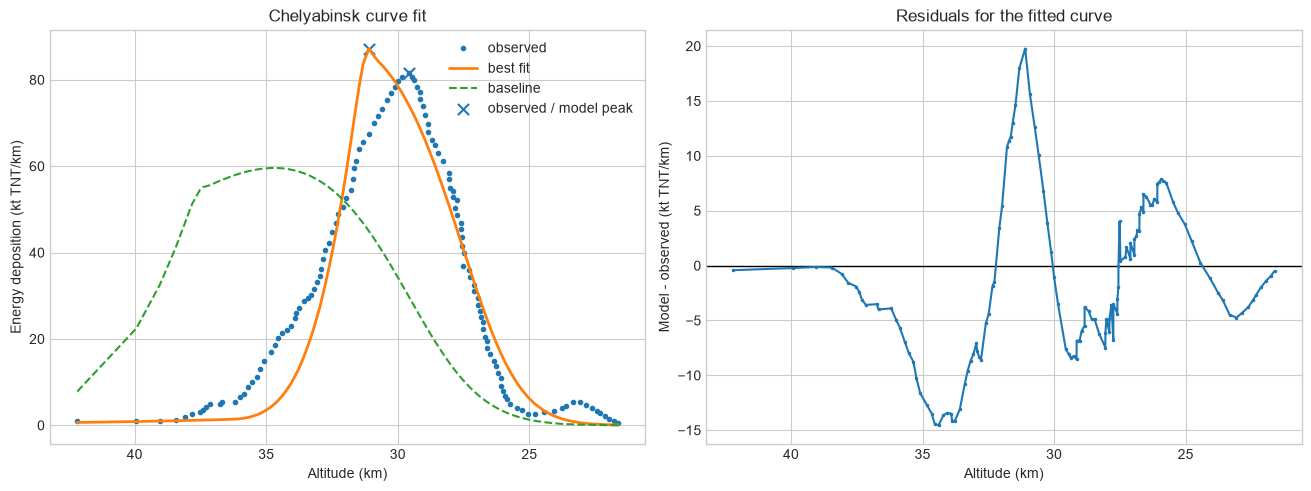

Observed peak: 81.50 kt/km at 29.56 km
Model peak: 87.21 kt/km at 31.10 km
Best-fit parameters within bounds: radius=9.012 m, strength=4.729 MPa, pancake_factor=6.290


In [13]:
fit_residual = best_model_dedz - observed_dedz
observed_peak_index = int(np.argmax(observed_dedz))
model_peak_index = int(np.argmax(best_model_dedz))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
axes[0].plot(
    observed_altitude_km,
    observed_dedz,
    "o",
    markersize=3,
    label="observed",
)
axes[0].plot(
    observed_altitude_km,
    best_model_dedz,
    linewidth=2,
    label="best fit",
)
axes[0].plot(
    observed_altitude_km,
    baseline_model_dedz,
    linestyle="--",
    linewidth=1.5,
    label="baseline",
)
axes[0].scatter(
    [observed_altitude_km[observed_peak_index], observed_altitude_km[model_peak_index]],
    [observed_dedz[observed_peak_index], best_model_dedz[model_peak_index]],
    marker="x",
    s=65,
    label="observed / model peak",
)
axes[0].set(
    xlabel="Altitude (km)",
    ylabel="Energy deposition (kt TNT/km)",
    title="Chelyabinsk curve fit",
)
axes[0].invert_xaxis()
axes[0].legend()

axes[1].axhline(0.0, color="black", linewidth=1)
axes[1].plot(observed_altitude_km, fit_residual, ".-", markersize=3)
axes[1].set(
    xlabel="Altitude (km)",
    ylabel="Model - observed (kt TNT/km)",
    title="Residuals for the fitted curve",
)
axes[1].invert_xaxis()
plt.show()

print(
    "Observed peak: "
    f"{observed_dedz[observed_peak_index]:.2f} kt/km at "
    f"{observed_altitude_km[observed_peak_index]:.2f} km"
)
print(
    "Model peak: "
    f"{best_model_dedz[model_peak_index]:.2f} kt/km at "
    f"{observed_altitude_km[model_peak_index]:.2f} km"
)
print(
    "Best-fit parameters within bounds: "
    f"radius={best_radius_m:.3f} m, "
    f"strength={best_strength_mpa:.3f} MPa, "
    f"pancake_factor={best_pancake_factor:.3f}"
)
